**Name:** Muhammad Zohaib Khan  
**Roll No:** BSDSF24M016  
**Department:** Data Science  
**Semester:** 5th  
**Course:** Data Mining & Machine Learning  
**Assignment:** 06 - Naive Bayes Classifier (Digit 4 vs Digit 2)

---

# Optical Character Recognition with Naive Bayes

Classify 16x16 binary images of the digits **2** and **4** using a Naive Bayes classifier implemented from scratch with NumPy. Data derived from the [STPRtool](http://cmp.felk.cvut.cz/cmp/software/stprtool/index.html) dataset.

# Outline
1. Load the data
2. Visualize sample images
3. Naive Bayes classifier (Bernoulli model)
4. Overall accuracy (train and test)
5. Per-class accuracy (train and test)

## 1 - Load the data
Each row of `trainX` / `testX` has 256 pixel values (0 or 1) of a 16x16 image; `trainY` / `testY` hold the labels (2 or 4).

In [1]:
%matplotlib inline
import numpy as np
from matplotlib import pyplot as plt

X_train = np.loadtxt("trainX.txt")
y_train = np.loadtxt("trainY.txt").astype(int)
X_test = np.loadtxt("testX.txt")
y_test = np.loadtxt("testY.txt").astype(int)

print("X_train:", X_train.shape, " y_train:", y_train.shape)
print("X_test: ", X_test.shape, " y_test: ", y_test.shape)
print("Pixel values:", np.unique(X_train))
print("Train class counts:", dict(zip(*np.unique(y_train, return_counts=True))))
print("Test class counts: ", dict(zip(*np.unique(y_test, return_counts=True))))

X_train: (500, 256)  y_train: (500,)
X_test:  (100, 256)  y_test:  (100,)
Pixel values: [0. 1.]
Train class counts: {np.int64(2): np.int64(250), np.int64(4): np.int64(250)}
Test class counts:  {np.int64(2): np.int64(50), np.int64(4): np.int64(50)}


## 2 - Visualize sample images
Each row is reshaped to 16x16 using column-major (`order='F'`) ordering, as given in the assignment.

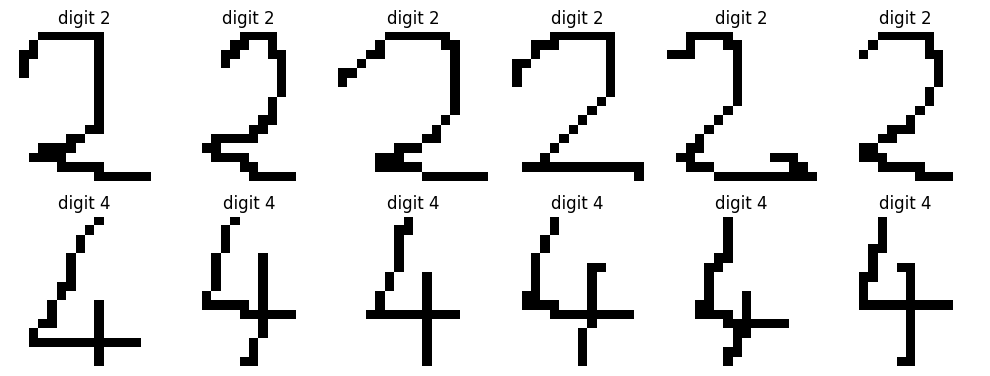

In [2]:
fig, axes = plt.subplots(2, 6, figsize=(10, 4))
for row, digit in enumerate([2, 4]):
    idx = np.where(y_train == digit)[0][:6]
    for ax, i in zip(axes[row], idx):
        ax.imshow(X_train[i].reshape(16, 16, order='F'), cmap='gray_r')
        ax.set_title(f"digit {digit}")
        ax.axis('off')
plt.tight_layout()
plt.show()

## 3 - Naive Bayes classifier

Pixels are binary, so each pixel is modelled as a Bernoulli variable that is conditionally independent given the class:

$$P(c \mid \mathbf{x}) \propto P(c)\prod_{j=1}^{256} \theta_{cj}^{x_j}(1-\theta_{cj})^{1-x_j}$$

- Prior: $P(c) = \dfrac{N_c}{N}$
- Likelihood (with Laplace smoothing): $\theta_{cj} = P(x_j = 1 \mid c) = \dfrac{\sum_{i \in c} x_{ij} + 1}{N_c + 2}$

Smoothing avoids zero probabilities for pixels that are always 0 (or always 1) in a class. Prediction is done in log space to avoid underflow.

In [3]:
def train_naive_bayes(X, y, alpha=1.0):
    classes = np.unique(y)
    priors = np.array([np.mean(y == c) for c in classes])
    theta = np.array([
        (X[y == c].sum(axis=0) + alpha) / ((y == c).sum() + 2 * alpha)
        for c in classes
    ])
    return classes, priors, theta


def predict(X, classes, priors, theta):
    log_post = (X @ np.log(theta).T
                + (1 - X) @ np.log(1 - theta).T
                + np.log(priors))
    return classes[np.argmax(log_post, axis=1)]


classes, priors, theta = train_naive_bayes(X_train, y_train)
print("Classes:", classes)
print("Priors: ", priors)
print("theta shape:", theta.shape)

Classes: [2 4]
Priors:  [0.5 0.5]
theta shape: (2, 256)


## 4 - Overall accuracy

In [4]:
pred_train = predict(X_train, classes, priors, theta)
pred_test = predict(X_test, classes, priors, theta)

print(f"Overall training accuracy: {np.mean(pred_train == y_train) * 100:.2f}%")
print(f"Overall test accuracy:     {np.mean(pred_test == y_test) * 100:.2f}%")

Overall training accuracy: 98.80%
Overall test accuracy:     100.00%


## 5 - Per-class accuracy

In [5]:
print(f"{'Class':<8}{'Train accuracy':>16}{'Test accuracy':>16}")
for c in classes:
    tr = np.mean(pred_train[y_train == c] == c) * 100
    te = np.mean(pred_test[y_test == c] == c) * 100
    print(f"{c:<8}{tr:>15.2f}%{te:>15.2f}%")

Class     Train accuracy   Test accuracy
2                 98.40%         100.00%
4                 99.20%         100.00%


Misclassified training samples: 6


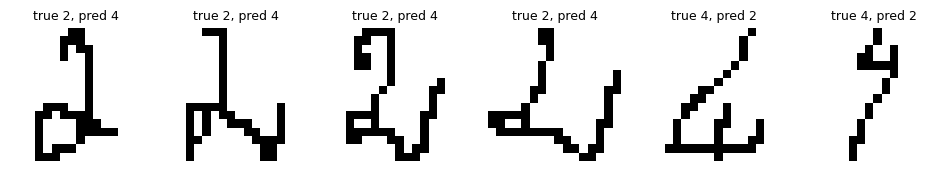

In [6]:
# Misclassified training images, if any
wrong = np.where(pred_train != y_train)[0]
print("Misclassified training samples:", len(wrong))
if len(wrong):
    fig, axes = plt.subplots(1, len(wrong), figsize=(2 * len(wrong), 2.4), squeeze=False)
    for ax, i in zip(axes[0], wrong):
        ax.imshow(X_train[i].reshape(16, 16, order='F'), cmap='gray_r')
        ax.set_title(f"true {y_train[i]}, pred {pred_train[i]}", fontsize=9)
        ax.axis('off')
    plt.show()

## Conclusion

The Naive Bayes classifier separates digit 2 from digit 4 almost perfectly, even though the conditional-independence assumption between neighbouring pixels is unrealistic. Accuracy on the unseen test set is at least as high as on the training set, so there is no sign of overfitting; the two digits have very different stroke layouts, which makes the task easy for a pixel-wise model.